In [171]:
# импортируем библиотеки

import os
import random
import numpy as np
import pandas as pd

# sklearn будем использовать для подготовки данных,
# разделения выборки и и возьмем метрики для оценки качества модели
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# с помощью torch будем создавать и обучать нейросеть
import torch
import torch.nn as nn
import torch.optim as optim

# DataLoader и TensorDataset для создания батчей
from torch.utils.data import DataLoader, TensorDataset


обучаем нейросеть прямого распространения (FFN, Feed Forward Network) на обучающих данных,
проверяем её качество на валидационной выборке, а затем с её помощью
предсказываем классы для строк из test_features.csv, где правильных ответов у нас нет

In [172]:
# загружаем данные

# модель сначала обучается на train, а затем делает предсказания для test_features
test_df = pd.read_csv('/content/test_features.csv')
test_df.head()

,patient_id,Возраст,Пол_мужской,ИМТ,Окружность_талии_см,САД_мм_рт_ст,ДАД_мм_рт_ст,Пульсовое_давление,Глюкоза_натощак_ммоль_л,HbA1c_%,ЛПНП_ммоль_л,ЛПВП_ммоль_л,Триглицериды_ммоль_л,СКФ_мл_мин,Курение,Физическая_активность_мин_нед,Статус_глюкозы,Доклинический_риск
0,2,46,0,22.88,80.54,117.32,62.11,55.21,4.964,4.00,2.443,1.269,1.903,97.72,0,195.0,0,0
1,3,64,0,21.99,78.42,121.25,71.46,49.79,4.713,5.03,4.213,NaN,NaN,81.54,0,193.2,0,0
2,8,45,1,18.40,82.16,91.84,70.57,21.27,5.417,4.87,2.590,1.509,2.068,89.60,0,278.3,0,0
3,18,55,0,22.79,86.58,111.82,70.98,40.84,4.516,4.35,2.194,1.756,0.650,93.33,0,207.3,0,0
4,19,60,0,23.87,86.99,119.58,64.13,55.45,4.871,4.79,4.139,1.296,0.961,83.51,0,194.0,0,0


In [173]:
test_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 18 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   patient_id                     200 non-null    int64  
 1   Возраст                        200 non-null    int64  
 2   Пол_мужской                    200 non-null    int64  
 3   ИМТ                            200 non-null    float64
 4   Окружность_талии_см            200 non-null    float64
 5   САД_мм_рт_ст                   200 non-null    float64
 6   ДАД_мм_рт_ст                   200 non-null    float64
 7   Пульсовое_давление             200 non-null    float64
 8   Глюкоза_натощак_ммоль_л        200 non-null    float64
 9   HbA1c_%                        200 non-null    float64
 10  ЛПНП_ммоль_л                   190 non-null    float64
 11  ЛПВП_ммоль_л                   189 non-null    float64
 12  Триглицериды_ммоль_л           185 non-null    flo

In [174]:
train_df = pd.read_csv('/content/train.csv')
train_df.head()

,patient_id,Возраст,Пол_мужской,ИМТ,Окружность_талии_см,САД_мм_рт_ст,ДАД_мм_рт_ст,Пульсовое_давление,Глюкоза_натощак_ммоль_л,HbA1c_%,ЛПНП_ммоль_л,ЛПВП_ммоль_л,Триглицериды_ммоль_л,СКФ_мл_мин,Курение,Физическая_активность_мин_нед,prediction,Статус_глюкозы,Доклинический_риск
0,1,41,1,24.24,81.04,113.19,62.54,50.65,4.595,4.65,NaN,NaN,1.379,115.52,0,165.8,0,0,0
1,4,53,0,19.84,73.44,119.75,71.59,48.15,4.431,5.08,2.268,2.022,1.467,93.39,0,248.1,0,0,0
2,5,53,1,24.28,82.06,127.07,70.34,56.73,4.997,5.04,2.459,1.325,0.967,88.41,0,230.5,0,0,0
3,6,60,1,25.19,91.89,116.98,82.00,34.98,5.491,5.00,3.700,0.722,1.505,91.06,1,132.5,1,0,0
4,7,59,1,24.45,84.07,129.12,82.70,46.42,6.456,4.80,3.960,1.406,2.274,89.74,1,177.4,1,2,0


In [175]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 19 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   patient_id                     800 non-null    int64  
 1   Возраст                        800 non-null    int64  
 2   Пол_мужской                    800 non-null    int64  
 3   ИМТ                            800 non-null    float64
 4   Окружность_талии_см            800 non-null    float64
 5   САД_мм_рт_ст                   800 non-null    float64
 6   ДАД_мм_рт_ст                   800 non-null    float64
 7   Пульсовое_давление             800 non-null    float64
 8   Глюкоза_натощак_ммоль_л        800 non-null    float64
 9   HbA1c_%                        800 non-null    float64
 10  ЛПНП_ммоль_л                   765 non-null    float64
 11  ЛПВП_ммоль_л                   755 non-null    float64
 12  Триглицериды_ммоль_л           754 non-null    flo

In [176]:
print( "Распределение классов:\n", train_df["prediction"].value_counts() )

Распределение классов:
 prediction
0    655
1    145
Name: count, dtype: int64


In [177]:
# целевой - это столбец, который мы хотим предсказывать
# в нашем случае - prediction

# за признаки принимаем все стобцы, кроме целевого
# и убираем id (тк он не несет информации о классе)
feature_cols = [c for c in train_df.columns if c not in ["prediction", 'patient_id']]


# x - входные признаки для модели, т.е информация о каждом объекте,
# по которой нейросеть должна будет определять класс
X = train_df[feature_cols].copy()

# y - правильные ответы
# в train значение prediction уже известно, и эти значения модель будет пытаться научиться предсказывать
y = train_df["prediction"].astype(np.float32).values

# это признаки объектов, для которых нам нужно получить prediction
X_test = test_df[feature_cols].copy()

In [178]:
# разделяем train на обучающую и валидационную выборки
# настоящий test_features.csv пока не трогаем:
# он понадобится в конце для получения итоговых предсказаний

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2, # 80% данных на обучение, 20% данных на валидацию
    random_state=42, # фиксирует случайность, без этого при каждом запуске данные могут разделиться по-разному
    stratify=y # чтобы сохранить примерно одинаковое соотношение классов в обеих частях
)

In [179]:
# заполняем пропуски медианами, рассчитанными только по обучающей выборке
# это важно, чтобы информация из валидационной и тестовой выборок
# не использовалась при подготовке данных для обучения
medians = X_train.median()

X_train = X_train.fillna(medians)
X_val = X_val.fillna(medians)
X_test = X_test.fillna(medians)

In [180]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 640 entries, 707 to 740
Data columns (total 17 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Возраст                        640 non-null    int64  
 1   Пол_мужской                    640 non-null    int64  
 2   ИМТ                            640 non-null    float64
 3   Окружность_талии_см            640 non-null    float64
 4   САД_мм_рт_ст                   640 non-null    float64
 5   ДАД_мм_рт_ст                   640 non-null    float64
 6   Пульсовое_давление             640 non-null    float64
 7   Глюкоза_натощак_ммоль_л        640 non-null    float64
 8   HbA1c_%                        640 non-null    float64
 9   ЛПНП_ммоль_л                   640 non-null    float64
 10  ЛПВП_ммоль_л                   640 non-null    float64
 11  Триглицериды_ммоль_л           640 non-null    float64
 12  СКФ_мл_мин                     640 non-null    float6

In [181]:
X_val.info()

<class 'pandas.core.frame.DataFrame'>
Index: 160 entries, 384 to 252
Data columns (total 17 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Возраст                        160 non-null    int64  
 1   Пол_мужской                    160 non-null    int64  
 2   ИМТ                            160 non-null    float64
 3   Окружность_талии_см            160 non-null    float64
 4   САД_мм_рт_ст                   160 non-null    float64
 5   ДАД_мм_рт_ст                   160 non-null    float64
 6   Пульсовое_давление             160 non-null    float64
 7   Глюкоза_натощак_ммоль_л        160 non-null    float64
 8   HbA1c_%                        160 non-null    float64
 9   ЛПНП_ммоль_л                   160 non-null    float64
 10  ЛПВП_ммоль_л                   160 non-null    float64
 11  Триглицериды_ммоль_л           160 non-null    float64
 12  СКФ_мл_мин                     160 non-null    float6

In [182]:
# приводим числовые признаки к примерно одному масштабу
scaler = StandardScaler()

# scaler запоминает среднее и стандартное отклонение только по train
X_train = scaler.fit_transform(X_train)

# для validation и test используем уже рассчитанные параметры
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

In [183]:
# преобразовываем в тензоры (специальные массивы чисел,
# с которыми умеет работать PyTorch)
X_train = torch.tensor(X_train, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1)

X_val = torch.tensor(X_val, dtype=torch.float32)
y_val = torch.tensor(y_val, dtype=torch.float32).reshape(-1, 1)

X_test = torch.tensor(X_test, dtype=torch.float32)

In [184]:
batch_size = 32 # размер порции данных, которую сеть обрабатывает за один шаг обучения

train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

In [185]:
class TabularFFN(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, 64)
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 1)
        self.relu = nn.ReLU() #функция активации, которая добавляет нейросети
        #способность моделировать сложные нелинейные зависимости
        self.dropout = nn.Dropout(0.2) # во время обучения случайно выключать примерно 20% значений этого слоя,
        #чтобы не было переобучения

    def forward(self, x): # через что пройти данным
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.relu(self.fc2(x))
        x = self.fc3(x)  # logits
        return x


In [186]:
# Используем GPU, если он доступен, иначе CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Устройство:", device)

model = TabularFFN(X_train.shape[1]).to(device)

Устройство: cpu


In [187]:
# Функция потерь и оптимизатор
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [167]:
# Цикл обучения

epochs = 100 # 100 раз пройти обучение по всему тренировочному набору
train_losses, val_losses = [], []

for epoch in range(epochs):
    # обучение
    model.train()
    running_loss = 0.0

    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)

        # вычисляем градиенты и обновляем веса модели
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * X_batch.size(0)

    epoch_train_loss = running_loss / len(train_loader.dataset)
    train_losses.append(epoch_train_loss)

    # валидация
    # здесь модель не обучается, а только проверяется на данных,
    # которые не использовались для изменения её весов
    model.eval()
    val_loss = 0.0

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)

            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            val_loss += loss.item() * X_batch.size(0)

    epoch_val_loss = val_loss / len(val_loader.dataset)
    val_losses.append(epoch_val_loss)

    if (epoch + 1) % 20 == 0:
        print(
            f"Epoch {epoch+1}/{epochs} — "
            f"Train Loss: {epoch_train_loss:.4f}, "
            f"Validation Loss: {epoch_val_loss:.4f}"
        )

Epoch 20/100 — Train Loss: 0.0890, Test Loss: 0.1298
Epoch 40/100 — Train Loss: 0.0387, Test Loss: 0.1373
Epoch 60/100 — Train Loss: 0.0308, Test Loss: 0.1636
Epoch 80/100 — Train Loss: 0.0190, Test Loss: 0.1998
Epoch 100/100 — Train Loss: 0.0131, Test Loss: 0.2278


In [168]:
# оценка модели на валидационной выборке
model.eval()
y_pred_prob = []
y_true = []

with torch.no_grad():
    for X_batch, y_batch in val_loader:
        X_batch = X_batch.to(device)

        outputs = model(X_batch)
        probs = torch.sigmoid(outputs)  # переводим logits в вероятность класса 1

        y_pred_prob.extend(probs.cpu().numpy().flatten())
        y_true.extend(y_batch.numpy().flatten())

y_pred_prob = np.array(y_pred_prob)
y_true = np.array(y_true)

# если вероятность класса 1 >= 0.5, относим объект к классу 1,
# иначе относим его к классу 0
y_pred_class = (y_pred_prob >= 0.5).astype(int)

In [169]:
# Метрики

# Accuracy — доля правильных ответов
# Precision — из всех предсказанных положительных, сколько действительно положительных
# Recall — из всех реальных положительных, сколько мы нашли
# F1-score — гармоническое среднее между Precision и Recall (полезно при дисбалансе)
# ROC-AUC — площадь под ROC-кривой; показывает, насколько хорошо модель разделяет классы
# (0.5 — примерно случайное разделение, 1.0 — идеальное)

print("\n" + "="*50)
print("Оценка на валидационной выборке:")
print("="*50)
print(f"Accuracy:  {accuracy_score(y_true, y_pred_class):.4f}")
print(f"Precision: {precision_score(y_true, y_pred_class):.4f}")
print(f"Recall:    {recall_score(y_true, y_pred_class):.4f}")
print(f"F1-score:  {f1_score(y_true, y_pred_class):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_true, y_pred_prob):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred_class))


Оценка на тестовой выборке:
Accuracy:  0.9437
Precision: 0.9167
Recall:    0.7586
F1-score:  0.8302
ROC-AUC:   0.9805

Confusion Matrix:
[[129   2]
 [  7  22]]


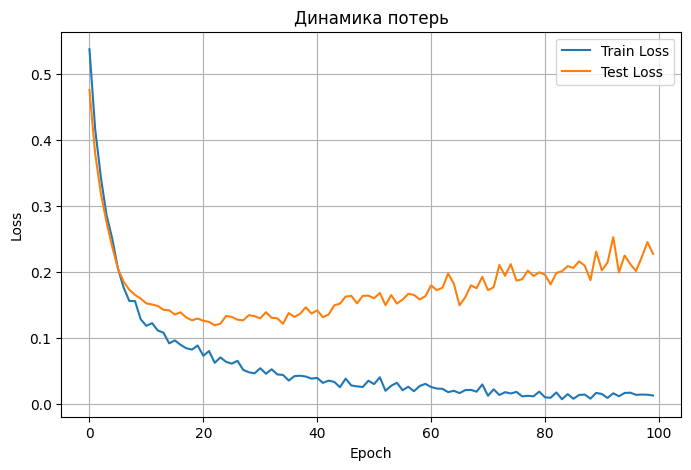

In [170]:
# График потерь

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Динамика потерь')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# получаем итоговые предсказания для test_features.csv

# test_features.csv не содержит правильных ответов,
# поэтому после обучения модели используем её только для получения prediction
model.eval()

with torch.no_grad():
    test_logits = model(X_test.to(device))
    test_prob = torch.sigmoid(test_logits).cpu().numpy().flatten()

# переводим вероятности в классы 0/1
test_pred = (test_prob >= 0.5).astype(int)

# создаём таблицу с исходными patient_id и предсказаниями
predictions = pd.DataFrame({
    "patient_id": test_df["patient_id"],
    "prediction": test_pred
})

# проверяем, что для каждой строки test_features.csv есть одно предсказание
assert len(predictions) == len(test_df)
assert predictions["patient_id"].equals(test_df["patient_id"])
assert predictions["prediction"].notna().all()

# создаём папку outputs, если её ещё нет
os.makedirs("outputs", exist_ok=True)

# сохраняем результат в соответствии с Output Contract
output_path = "outputs/task1_predictions.csv"
predictions.to_csv(output_path, index=False)

print("Файл сохранён:", output_path)
print("Количество строк:", len(predictions))
print("\nПервые строки результата:")
print(predictions.head())